---
title: Significance testing
format:
    # typst:
    #     echo: false

    revealjs:
        smaller: true
        code-line-numbers: false
        echo: false
        include-in-header:
            - text: |
                <style>
                .reveal h1, .reveal h2, .reveal h3, .reveal h4 { text-align: center; }
                </style>
            - text: |
                <style>
                .center { text-align: center; display: block; }
                </style>
            - text: |
                <style>
                .orange { color: orange; display: block; }
                </style>
            - text: |
                <style>
                .white { color: white; display: block; }
                </style>
            - text: |
                <style>
                .reveal pre.sourceCode { font-size: 20px; }
                </style>

execute:
  enabled: false
editor:
    render-on-save: true
progress: true
incremental: true
slide-level: 3
jupyter: python3
display_name: "Python 3.11.5"
---

In [1]:
#| output: false

import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.stats import t, ttest_ind
from numpy.random import normal

mpl.rc_file('/home/njs/miniconda3/lib/python3.11/site-packages/matplotlib/mpl-data/matplotlibrc')

custom_params = {"axes.spines.right": False, "axes.spines.top": False}
sns.set_theme('talk', style='white', rc=custom_params)

### How compatible are my data?

- How compatible are the data with the assumption that light conditions **do not** affect sunflower height?
- How compatible are the data with the assumption that hyena laughter fundamental frequency is **not correlated** with age?
- How compatible are the data with the assumption that average beak widths **did not change** between 1976 and 1978?

### How compatible are my data?

- In all cases we assume either **no effect** or **no correlation** or **no cause** or **no difference** 
- And then ask how compatible are the data under this assumption
- This assumption is called a **null hypothesis**: 
    - How compatible are the data with the null hypothesis?
- This is the question you always ask yourself when doing significance testing

### Question 1: Do sunflowers grow taller when shaded?

In [2]:
def plot_sunflower(sunflower, diff=False):
    ax = sns.pointplot(data=sunflower, y='Height after 3 months (cm)', x='Treatment', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3)
    sns.swarmplot(data=sunflower, y='Height after 3 months (cm)', x='Treatment', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
    ax.set_xlabel('Light treatment');
    ax.set_title('Sunflower height in sunlight or shade');

    if diff:
        xbar = sunflower.groupby('Treatment').mean()
        y0  = float(xbar.iloc[0].values[0])
        y1  = float(xbar.iloc[1].values[0])
        ax.annotate('', xy=(0.5, y0), xytext=(0.5, y1), arrowprops={'arrowstyle':'<->', 'color':'k'})
        ax.text(s=f'{y1-y0:.1f} cm', x=0.53, y=0.5*(y0+y1), va='center', rotation=90);


    image = plt.imread('Images/sunflower.jpg')
    inset_ax = ax.inset_axes([0.05, 0.58, 0.4, 0.4])
    inset_ax.imshow(image)
    inset_ax.axis('off')


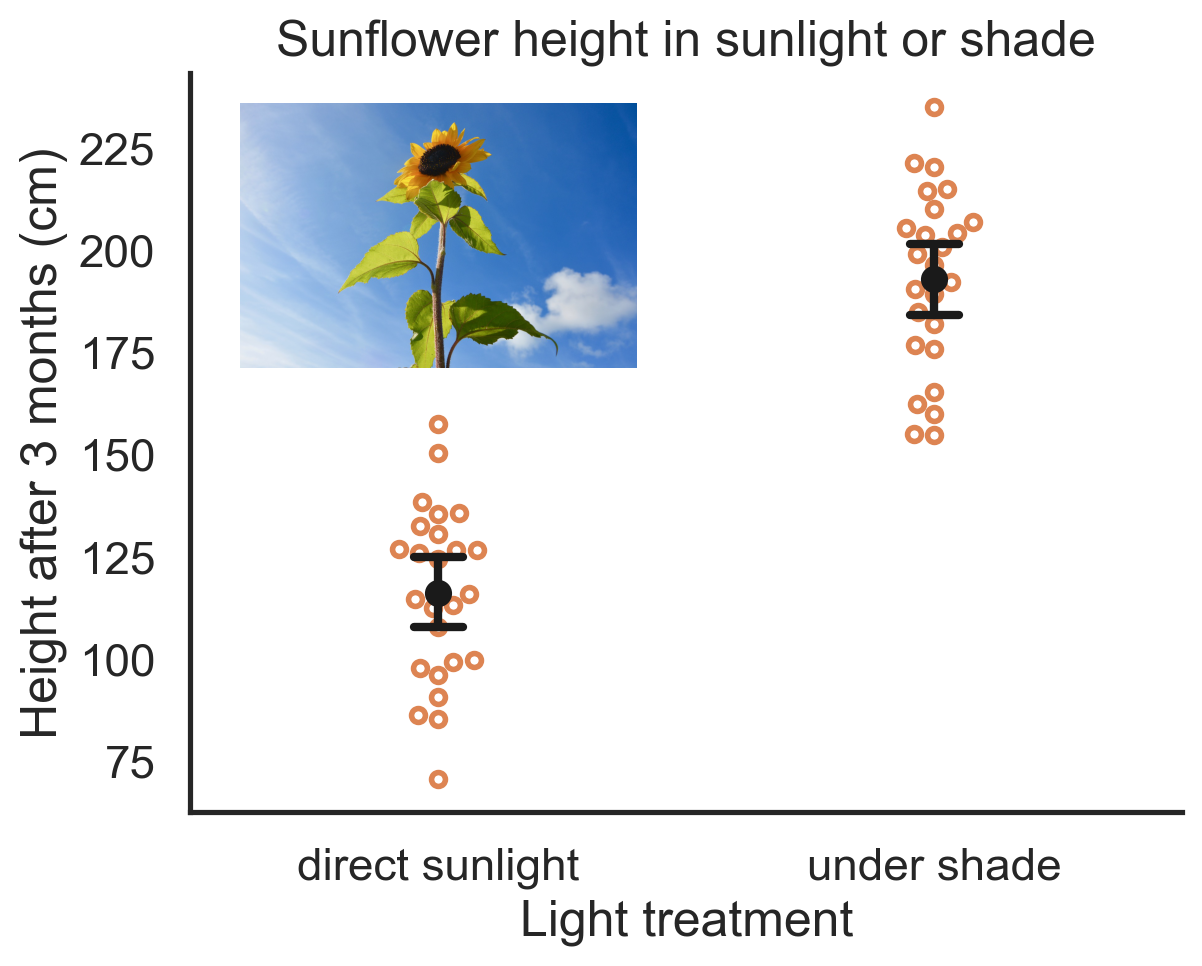

In [3]:
#| fig-align: center

sunflower = pd.DataFrame(np.array([normal(120, 20, 25), normal(200, 20, 25)]).T, columns=['direct sunlight', 'under shade'])
sunflower = sunflower.melt(value_name='Height after 3 months (cm)', var_name='Treatment')

plot_sunflower(sunflower)
plt.savefig('Images/sunflower_data.png', bbox_inches='tight')

The data are clear cut. They are **incompatible** with the null hypothesis.

### Question 2: Is hyena laughter fundamental frequency correlated with age?

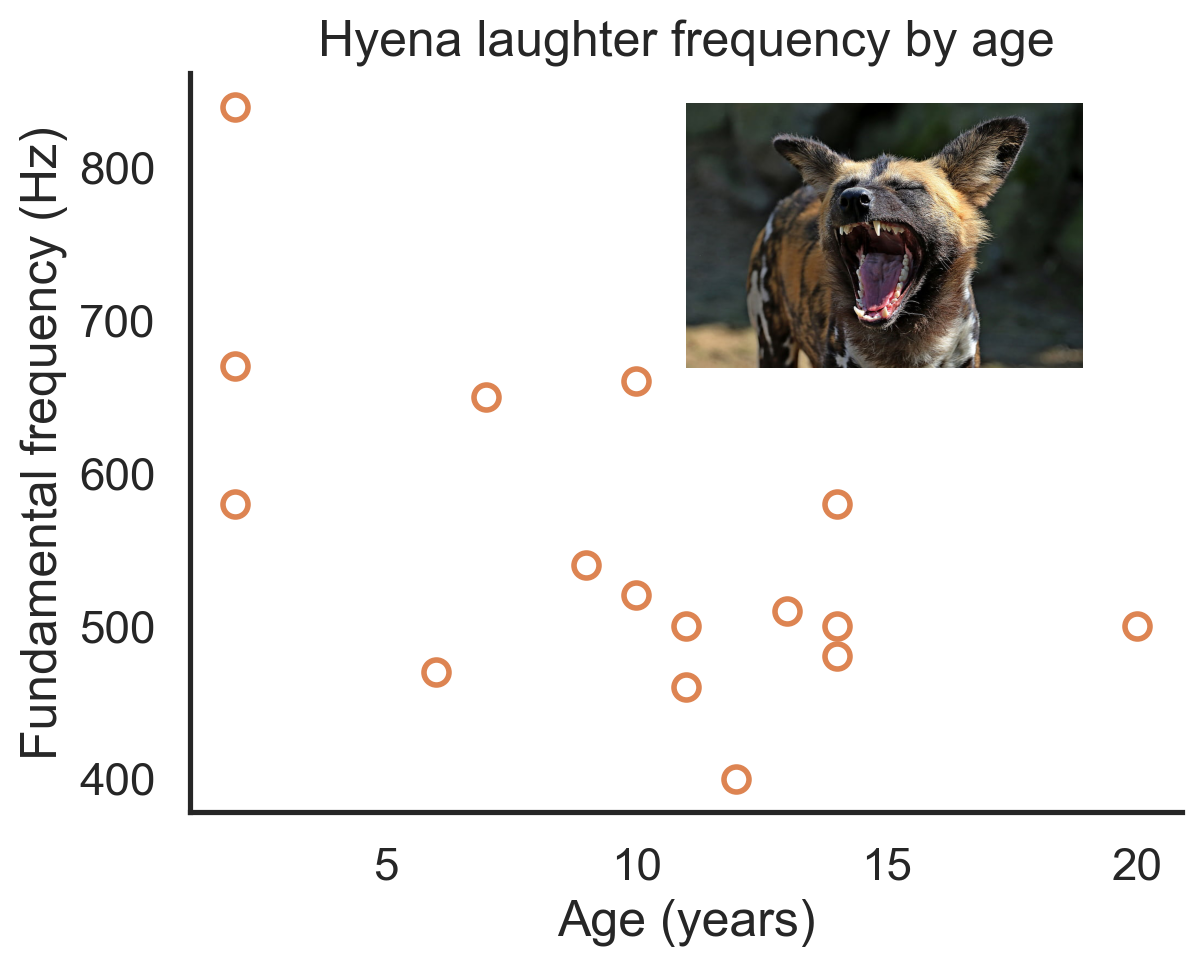

In [4]:
#| fig-align: center
hl = pd.read_csv('../Datasets/hyena_laughter.csv')
ax = sns.scatterplot(data=hl, x='Age_years', y='Fundamental_frequency_Hz', marker='o', facecolor='w', edgecolor='C1', linewidth=2)
ax.set_title('Hyena laughter frequency by age')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Fundamental frequency (Hz)');

image = plt.imread('Images/hyena.jpg')
inset_ax = ax.inset_axes([0.5, 0.58, 0.4, 0.4])
inset_ax.imshow(image)
inset_ax.axis('off')

plt.savefig('Images/hyena_data.png', bbox_inches='tight')

Difficult to tell how compatible the data are with the null hypothesis. Say 50:50.

More data would clarify if there was a correlation or not.

### Question 3: Are ground finch beak widths different in 1976 and 1978?

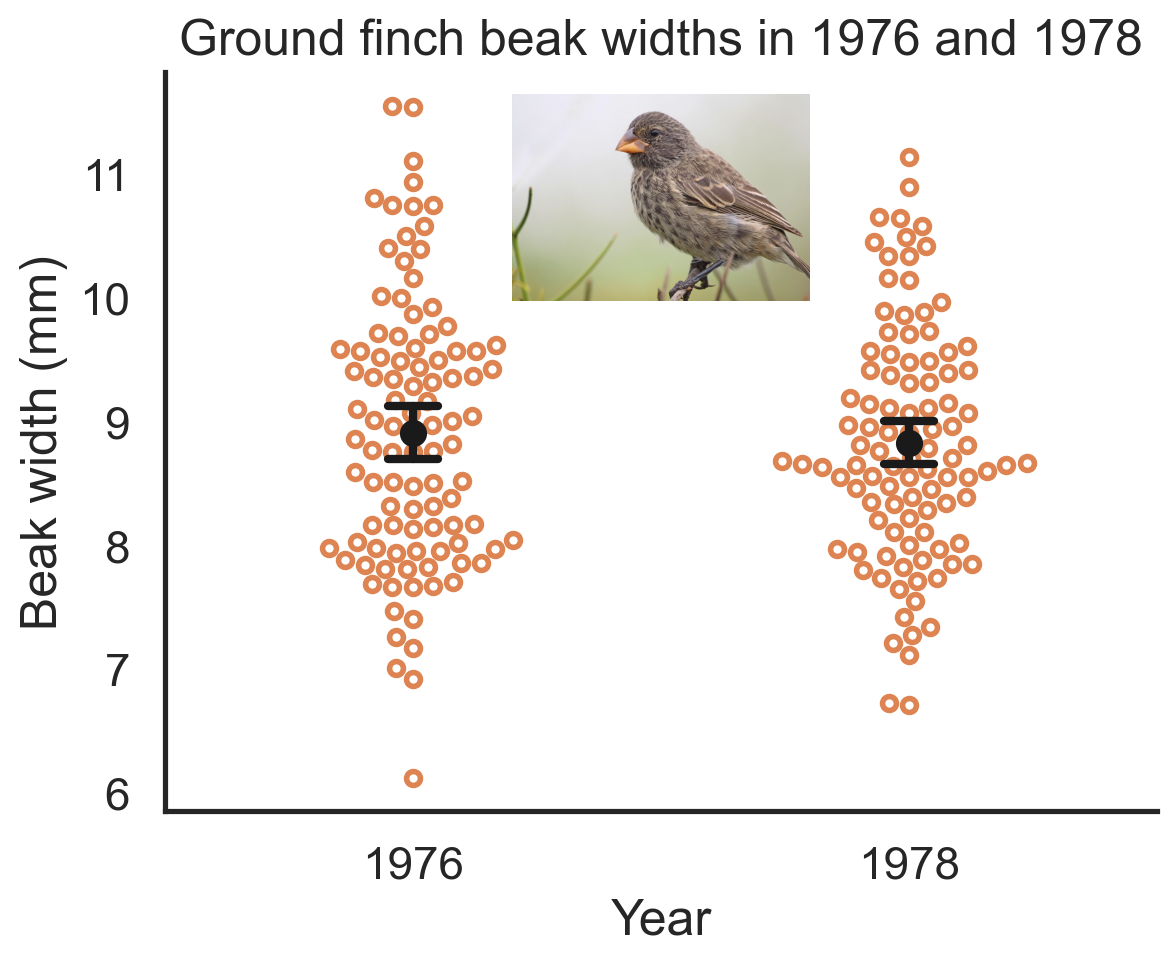

In [5]:
#| fig-align: center

bw = pd.DataFrame(np.array([normal(9, 1, 100), normal(8.75, 1, 100)]).T, columns=['1976', '1978'])
bwm = bw.melt(value_name='Beak width (mm)', var_name='Year')

def plot_finch(bwm):
    sns.swarmplot(data=bwm, y='Beak width (mm)', x='Year', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
    ax = sns.pointplot(data=bwm, y='Beak width (mm)', x='Year', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3)
    ax.set_title('Ground finch beak widths in 1976 and 1978');

    image = plt.imread('Images/ground_finch.jpg')
    inset_ax = ax.inset_axes([0.35, 0.68, 0.3, 0.3])
    inset_ax.imshow(image)
    inset_ax.axis('off')

plot_finch(bwm)

Data looks compatible with the null hypothesis.

But it is actually not because there are so many observations.

### <span style="color: white;">Why do we need statistics?</span> {background-image="Images/constellations.jpg"}

::: {.white}
- People are excellent at seeing patterns in completely random noise. 

- This is called apophenia.

- Scientists are no different. 

<br>
<br>
<br>
<br>
<br>

- They are excellent at seeing "interesting" results in their data if it confirms their pre-conceived biases even when their data are just noise and contain nothing of interest.
- Statistics (when done properly) reduces the risk we make fools of ourselves by claiming noise in our data as something interesting.

:::

### Unfortunately, statistics is often not done properly

Scientists publish false and exaggerated claims

![](Images/ioannidis.png){fig-align="center"}

John Ioannadis found that **one third** of the most highly cited medical papers (1000+ citations) between 1997 and 2003 were either contradicted or found to have exaggerated results by subsequent studies

-   in itself this is not a problem: science is self correcting - an honest mistake can be corrected when other scientists try to replicate early studies and fail

-   but statistics done poorly—leading to exaggerated claims—wastes time, money and resources

### Why is statistics not done properly? 

#### A brief history of stats

- You may have formed the impression, given how you were taught in School and in Year 1 of University, that the way statistics is done is a given truth. That there is just one way to do statistics.

- This is not true.

- The concepts and methods most scientists currently use were developed in the mid-20th century. 

- 21st-century statistics is moving on, but many scientists still use the old methods because that is the way they were taught.

- It's useful to know a little of the history of stats in order to understand the current state of affairs.

### Fisherian view

:::: {.columns}
::: {.column width="30%"}
![](Images/fisher.jpeg)
:::
::: {.column width="70%"}

::: {.fragment}
Fisher was a brilliant but controversial figure. He is one of the founders of the modern synthesis of Darwinian natural selection, Mendelian genetics and population genetics.
:::
::: {.fragment}
His foundational statistical work was published in 1925, *Statistics for Research Workers*, in which he sought: 

> “to put into the hands of research workers, and especially of biologists, the means of applying statistical tests accurately to numerical data.”
:::
:::
::::

### Fisherian view


:::: {.columns}
::: {.column width="30%"}
![](Images/fisher.jpeg)
:::
::: {.column width="70%"}

- His view was that we collect data and use it to measure the strength of evidence against the null hypothesis. 
- The strength of evidence against the null is termed *P* (for probability) with a value between 0 and 1.
- If *P* is high: the data are compatible with the null - the difference observed is likely due to random chance
- If *P* is low: the data are incompatible with the null - the difference observed is not likely due to random chance but due to something real
:::
::::


### Fisherian view

:::: {.columns}
::: {.column width="30%"}
![](Images/fisher.jpeg)
:::
::: {.column width="70%"}

- Fisher formalised and popularised the term "statistically significant". So his method is thought of as a "significance test".

- He is also credited (blamed) for the 5% cut-off for *P* below which a test is deemed "statistically significant".

- But this is not quite true. Fisher viewed *P* as a continuous measure of the strength of evidence against the null hypothesis, rather than a binary "significant/not significant" decision.
:::
::::

### Neyman-Pearson view

:::: {.columns}
::: {.column width="30%"}
![](Images/neymanpearson.jpg)
:::
::: {.column width="70%"}


- Neyman was a Polish mathematician and Pearson was a British statistician.

- Published in 1933; more holistic method than Fisher's. How one should plan experiments and what to decide once an experiment is complete.

- Their method says you must make a yes/no decision about the truth of the null hypothesis. So their method is thought of as a "hypothesis test"

:::
::::

### Bayesian view

:::: {.columns}
::: {.column width="30%"}
![Maybe Thomas Bayes 1701-1761](Images/Thomas_Bayes.gif)
:::
::: {.column width="70%"}


- The Reverend Thomas Bayes was a student at Edinburgh University 300 years ago. 

- Bayesian concepts came before Fisher, Neyman and Pearson.

- They have been further developed in the last 75 years.

- But required the advent of modern computers to become a useful statistical method.

- How to update your personal degree of belief in something (e.g., a parameter value, a set of hypotheses)

:::
::::

### Bayesian view

:::: {.columns}
::: {.column width="30%"}
![Maybe Thomas Bayes 1701-1761](Images/Thomas_Bayes.gif)
:::
::: {.column width="70%"}

::: {.fragment}
**First state your prior belief**

Before doing an experiment quantify your personal prior belief based on expert knowledge, previous studies, etc
:::

-   For example, I believe the odds of Darwinian natural selection against Lamarckism is 10:1

::: {.fragment}
**Next collect some data to update your belief**
:::

-   I now believe the odds of Darwinian natural selection against Lamarckism is 100:1
:::
::::



### Bayesian view

:::: {.columns}
::: {.column width="30%"}
![Maybe Thomas Bayes 1701-1761](Images/Thomas_Bayes.gif)
:::
::: {.column width="70%"}

**And repeat**

- Use your new belief and new experiments to further update your belief, and so on...

- Requires a working knowledge of probability distributions, some maths such as integration and the ability to transform mathematical equations into computer code.

- So we won't consider this any further.
:::
::::

### Likelihood view

:::: {.columns}
::: {.column width="30%"}
::: {layout-nrow=2}
![](Images/fisher.jpeg){width=44%}
![](Images/Samuel_S_Wilks.jpg){width=50%}
![](Images/neymanpearson.jpg){width=97%}
:::
:::
::: {.column width="70%"}

- Developed in the 1930s by Fisher, Neyman, Pearson, Samuel Wilks, an American mathematician

- Calculate the relative strength of evidence of one hypothesis over another

- Again requires mathematical and coding knowledge, so we won't consider this any further.
:::
::::

### Different statistical philosophies

- Fisher asks: What is the strength of evidence in my data against a **null hypothesis**?

- Neyman-Pearson ask: In deciding for or against my **null hypothesis**, how many errors would I be willing to make if I were to repeat my experiment a large number of times?

- Bayes asks: By how much does my data update my beliefs in my **competing hypotheses**?

- Likelihood asks: What are the relative strengths of evidence between my **competing hypotheses** given my data?

### How statistics is used by most biologists

- Almost all biologists were educated in "classical statistics", also called "frequentist statistics".

- Classical statistics has been called an "inconsistent mishmash" of Fisherian and Neyman-Pearson methods[^1]. 
    - (This was thought to come about because Fisher and Neyman were bitter rivals with strong personalities, and 20^th^-century textbook authors didn't want to take sides, so they combined the two methods into a single method which is still taught and used today.)

- It's fair to say that most biologists are confused about statistics.

[^1]: Gigerenzer G (1998) We need statistical thinking, not statistical rituals. Behav Brain Sci  21:199–20

### How statistics is used by most biologists

- Most biologists think like Bayesians (multiple sources of evidence accumulated over time makes a hypothesis ever more or less likely).

- But when publishing research, most biologists use classical statistics (testing only null hypotheses and declaring any test that gives *P* < 0.05 as statistically significant).


### How statistics is used by most biologists

- But classical statistics is easy to misunderstand which causes biologists to

    -   unintentionally claim a significant result when it is not (very common)
    -   misuse it to fraudulently claim a significant result when it is not (rare)
        - Why? Because there is an incentive to cheat: scientific credibility, promotion, grant funding and publishing is contingent upon producing statistically significant science.

- Having said that, classical statistics mostly works for most biologists most of the time — discoveries are still made.


### The source of the problem: *P* < 0.05

- In unthinking classical statistics:

    - If *P* < 0.05 we reject the null hypothesis and declare a "statistically significant result"
    - If *P* > 0.05 we do not reject the null hypothesis and declare a "statistically non-significant result"

- However, the threshold of 0.05 (or any threshold for that matter) is completely arbitrary and has no scientific justification.

- Its adoption in 20<sup>th</sup>-century textbooks forced biologists into pursuing the holy-grail of *P* < 0.05.

### How *P* < 0.05 became "significant"

Fisher viewed *P* as a continuous measure of evidence against the null hypothesis, e.g.,

- *P* = 0.2: insufficient evidence against the null hypothesis
- *P* = 0.0002 is very strong evidence against the null hypothesis

::: {.fragment}
so it's exact value is important.
:::

### How *P* < 0.05 became "significant"
:::: {.columns}
::: {.column width="50%"}

- However, 100 years ago, before computers, manually calculating the exact value of *P* was very tedious. 

- Instead statisticians used tables for various tests (e.g., *t*, $\chi^2$, *F*) at fixed levels of *P*.

- Such tables were of immense benefit and a huge time saver for non-mathematically inclined scientists.

- So they became a core tool in the statistical analysis of data.

:::
::: {.column width="50%"}
![](Images/ttable.png)
:::
::::

### How *P* < 0.05 became "significant"

In addition, Fisher said in his 1925 book:

> "It is *convenient* to take this point [0.05] as a limit in judging whether a result is to be considered significant or not."

::: {.fragment}
This convenience became, over many years, an arbitrary convention:
:::

- *P* > 0.05: "not significant", an uninteresting, unpublishable result
- *P* < 0.05: "significant", an interesting, publishable result

::: {.fragment}
And this is how *P* < 0.05 came to mean "significant".
:::

### How *P* < 0.05 became "significant"

But for Fisher *P* \< 0.05 was a flexible, informal rule of thumb, not a scientific law.

In 1956 he wrote:

> "...no scientific worker has a fixed level of significance \[e.g., 0.05] at which from year to year, and in all circumstances, he rejects hypotheses; he rather gives his mind to each particular case in the light of his evidence and his ideas."

::: {.fragment .orange}
*P* < 0.05 is a completely arbitrary convention with no scientific justification.
:::

### Wooclap

### Why an arbitrary threshold is meaningless

![](Images/sig_not_sig.png){width=40%}

The data are almost identical. But 

::: {.nonincremental}
- A is not statistically significant
- B is statistically significant
:::

### Why an arbitrary threshold is meaningless

![](Images/sig_not_sig.png){width=40%}

This demonstrates that an arbitrary threshold, wherever it may be (0.001, 0.01, 0.05, etc), results in nonsense scientific conclusions when *P* is close to that threshold.

::: {.fragment}
The best course of action here would be to collect more data, which would move *P* away from 0.05. 
:::

### Searching for significance

#### Or how scientists make non-significant results significant

-  Removing data that look like outliers
-  Disregarding some of the data based on other variables
-  Trying different statistical tests until one gives *P* \< 0.05
-  Not correcting for multiple tests

::: {.fragment .orange}
This is called p-hacking and should not be done.
:::

### Searching for significance: Removing "outliers"


In [6]:
# #| output: false

# while True:
#     x1 = normal(200, 10, 10)
#     x2 = normal(200, 10, 10)
#     x1r = sorted(x1)
#     x2r = x2
#     xbar = np.mean(x1r)
#     s = np.std(x1r)
#     outlier = x1r[0]
#     x1r = x1r[1:]
#     p = stats.ttest_ind(x1, x2).pvalue
#     pr = stats.ttest_ind(x1r, x2r).pvalue
#     if outlier < xbar - 2.5*s and p > 0.051 and pr < 0.049:
#         print('p-value with raw data:', p)
#         print('p-value with rounded data:', pr)
#         break

In [7]:
# #| output: false

# s1 = pd.DataFrame({'value': x1, 'Group':1, '"Outlier" removed':'No'})
# s2 = pd.DataFrame({'value': x2, 'Group':2, '"Outlier" removed':'No'})
# s1r = pd.DataFrame({'value': x1r, 'Group':1, '"Outlier" removed':'Yes'})
# s2r = pd.DataFrame({'value': x2r, 'Group':2, '"Outlier" removed':'Yes'})

# df = pd.concat([s1, s2, s1r, s2r], ignore_index=True)
# # df.to_csv('../Datasets/removing_outlier.csv', index=False)

In [8]:
outlier = pd.read_csv('../Datasets/removing_outlier.csv')

x1 = outlier[outlier['"Outlier" removed'] == 'No'].query('Group == 1')
x2 = outlier[outlier['"Outlier" removed'] == 'No'].query('Group == 2')
x3 = outlier[outlier['"Outlier" removed'] == 'Yes'].query('Group == 1')
x4 = outlier[outlier['"Outlier" removed'] == 'Yes'].query('Group == 2')
p1 = stats.ttest_ind(x1['value'], x2['value']).pvalue # test A vs B (morning only)
p2 = stats.ttest_ind(x3['value'], x4['value']).pvalue # test A vs B (afternoon only)


:::: {.columns}
::: {.column width="50%"}
[Outlier not removed]{.center}

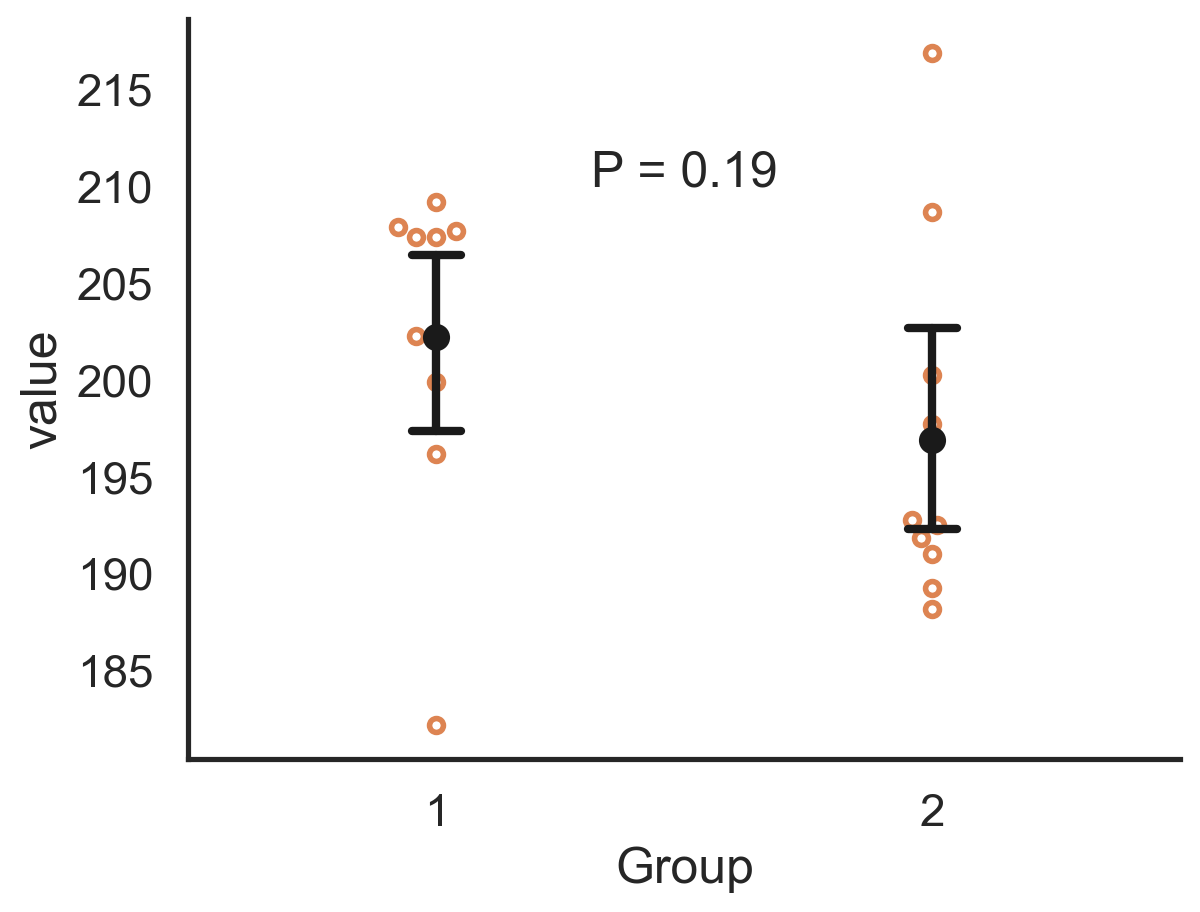

In [9]:
#| fig-align: center
#| fig-width: 10px

data = outlier[outlier['"Outlier" removed'] == 'No']
ax = sns.swarmplot(data=data, x='Group', y='value', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2);
ax.text(s=f'P = {p1:.2g}', x=0.5, y = 210, ha='center')
sns.pointplot(ax=ax, data=data, y='value', x='Group', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3);
ylims = ax.get_ylim()

:::
::: {.column width="50%"}
::: {.fragment}
[Outlier removed]{.center}

(180.4458636427108, 218.57926893852738)

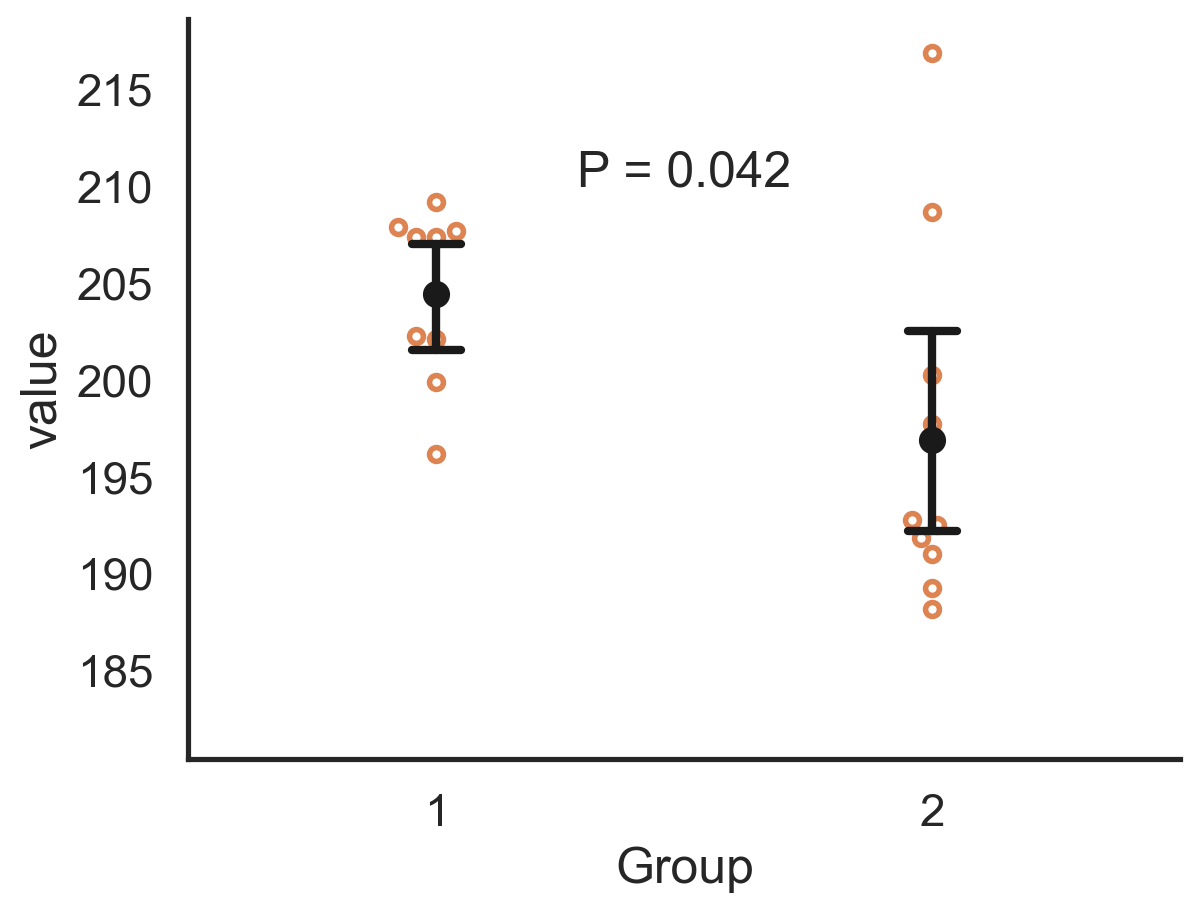

In [10]:
data = outlier[outlier['"Outlier" removed'] == 'Yes']
ax = sns.swarmplot(data=data, x='Group', y='value', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2);
ax.text(s=f'P = {p2:.2g}', x=0.5, y = 210, ha='center')
sns.pointplot(ax=ax, data=data, y='value', x='Group', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3)
ax.set_ylim(*ylims)



:::
:::
::::

### Searching for significance: Discarding subsets of data

#### Also called "slicing and dicing".

In [11]:
# while True:
#     x1 = normal(20, 2, 10) # morning A
#     x2 = normal(20, 2, 10) # afternoon A
#     x3 = normal(20, 2, 10) # morning B
#     x4 = normal(20, 2, 10) # afternoon B
#     xA = np.concatenate([x1, x2]) # combine morning
#     xB = np.concatenate([x3, x4]) # combine afternoon
#     p1 = stats.ttest_ind(xA, xB).pvalue # test A vs B (morning and afternoon combined)
#     p2 = stats.ttest_ind(x1, x3).pvalue # test A vs B (morning only)
#     p3 = stats.ttest_ind(x2, x4).pvalue # test A vs B (afternoon only)
#     # combined non-sig, morning only sig, afternoon non-sig
#     if 0.051 > p1 > 0.08 and p2 < 0.049 and p3 > 0.051:
#         print(f'{p1=}\n{p2=}\n{p3=}')
#         break


# s1 = pd.DataFrame({'Height (cm)': x1, 'Time':'morning', 'Fertiliser':'A'})
# s2 = pd.DataFrame({'Height (cm)': x2, 'Time':'afternoon', 'Fertiliser':'A'})
# s3 = pd.DataFrame({'Height (cm)': x3, 'Time':'morning', 'Fertiliser':'B'})
# s4 = pd.DataFrame({'Height (cm)': x4, 'Time':'afternoon', 'Fertiliser':'B'})

# df = pd.concat([s1, s2, s3, s4], ignore_index=True)
# df.to_csv('../Datasets/slicing.csv', index=False)

In [12]:
# #| output: false

slicing = pd.read_csv('../Datasets/slicing.csv')
xA = slicing.query('Fertiliser == "A"')
xB = slicing.query('Fertiliser == "B"')
x1 = xA.query('Time == "morning"')
x2 = xA.query('Time == "afternoon"')
x3 = xB.query('Time == "morning"')
x4 = xB.query('Time == "afternoon"')
p1 = stats.ttest_ind(xA['Height (cm)'], xB['Height (cm)']).pvalue # test A vs B (morning and afternoon combined)
p2 = stats.ttest_ind(x1['Height (cm)'], x3['Height (cm)']).pvalue # test A vs B (morning only)
p3 = stats.ttest_ind(x2['Height (cm)'], x4['Height (cm)']).pvalue # test A vs B (afternoon only)

::::: {.columns}
:::: {.column width="50%"}

::: {.fragment fragment-index=1}
For example, you plant 20 tulips and apply two different fertilisers called A and B. Six months later you measure their height all on the same day. 
:::

::: {.fragment fragment-index=2}
You get a non-significant difference in heights between the two fertilisers of *P* = 0.08, which is close to 0.05.
:::

::::

:::: {.column width="50%"}
::: {.fragment fragment-index=1}

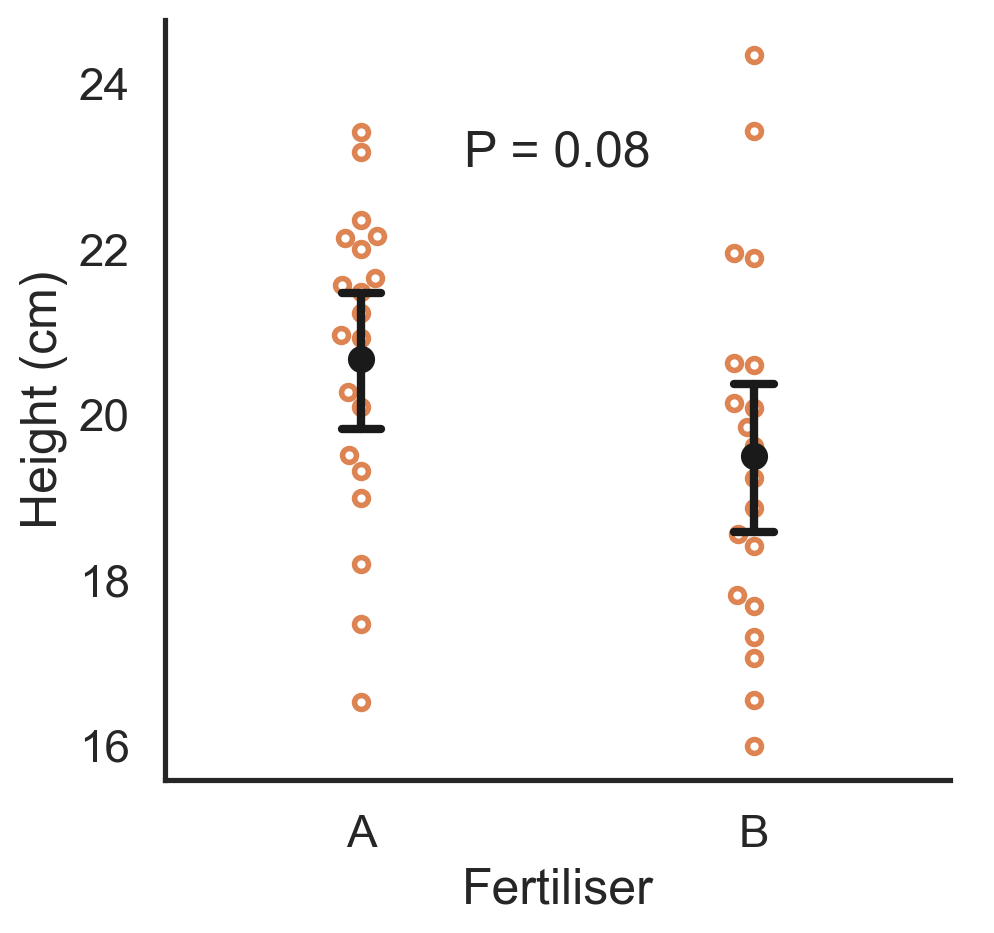

In [13]:
g = sns.catplot(data=slicing, x='Fertiliser', y='Height (cm)', kind='swarm', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
ax = g.axes[0][0]
ax.text(s=f'P = {p1:.2g}', x=0.5, y = 23, ha='center')
sns.pointplot(ax=ax, data=slicing, y='Height (cm)', x='Fertiliser', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3);


:::
::::
:::::

### Searching for significance: Discarding subsets of data

Being a good scientist you recorded the time of day you measured each plant. You measured half the tulips in the morning and the other half in the afternoon. 

::: {.fragment}
So you split the data into morning and afternoon measurements.
:::
::: {.fragment}

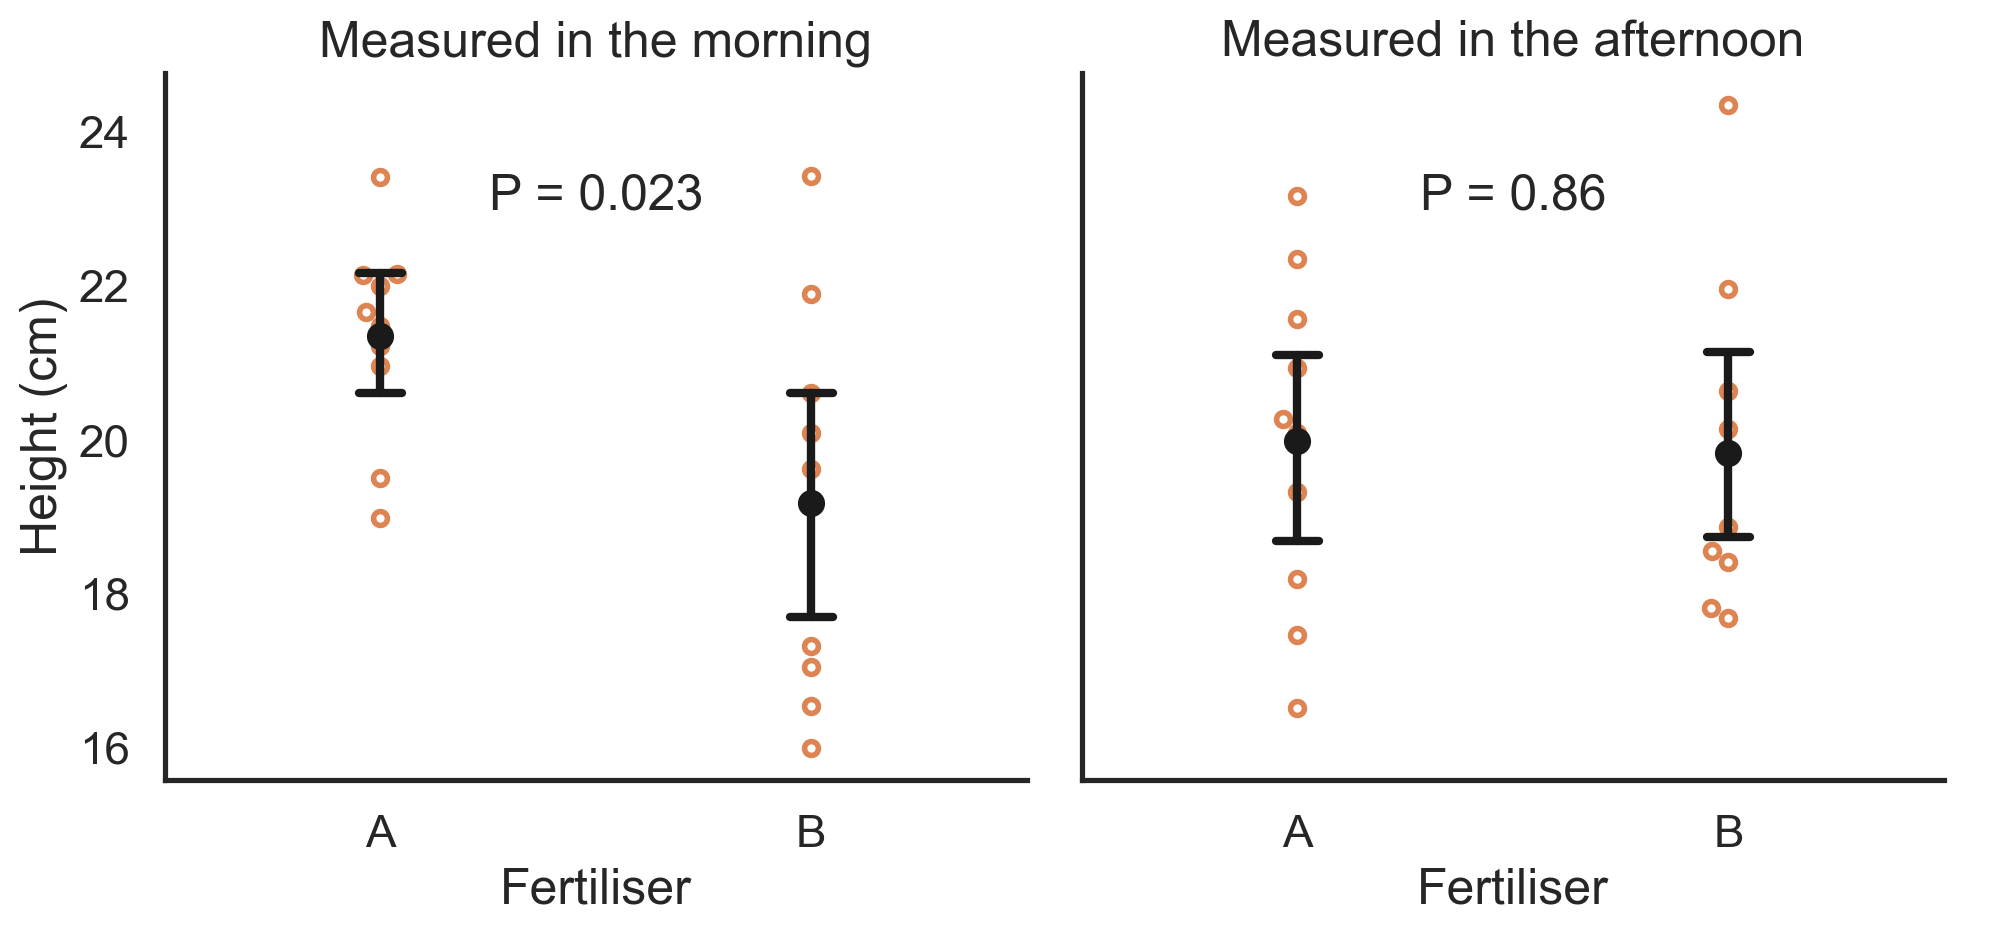

In [14]:

#| fig-align: center

g = sns.catplot(data=slicing, x='Fertiliser', y='Height (cm)', col='Time', kind='swarm', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2)
ax = g.axes[0][0]
ax.text(s=f'P = {p2:.2g}', x=0.5, y = 23, ha='center')
sns.pointplot(ax=ax, data=slicing.query('Time == "morning"'), y='Height (cm)', x='Fertiliser', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3)
ax = g.axes[0][1]
ax.text(s=f'P = {p3:.2g}', x=0.5, y = 23, ha='center')
sns.pointplot(ax=ax, data=slicing.query('Time == "afternoon"'), y='Height (cm)', x='Fertiliser', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3)
g.set_titles('Measured in the {col_name}');


:::

### Searching for significance: Discarding subsets of data

In the search for significance you justify to yourself that the afternoon measurements are unreliable—perhaps you had large lunch that made you drowsy and more error prone—so you discard them, never mentioning that you threw away some data.

::: {.fragment}
And you end up with a statistically significant result.

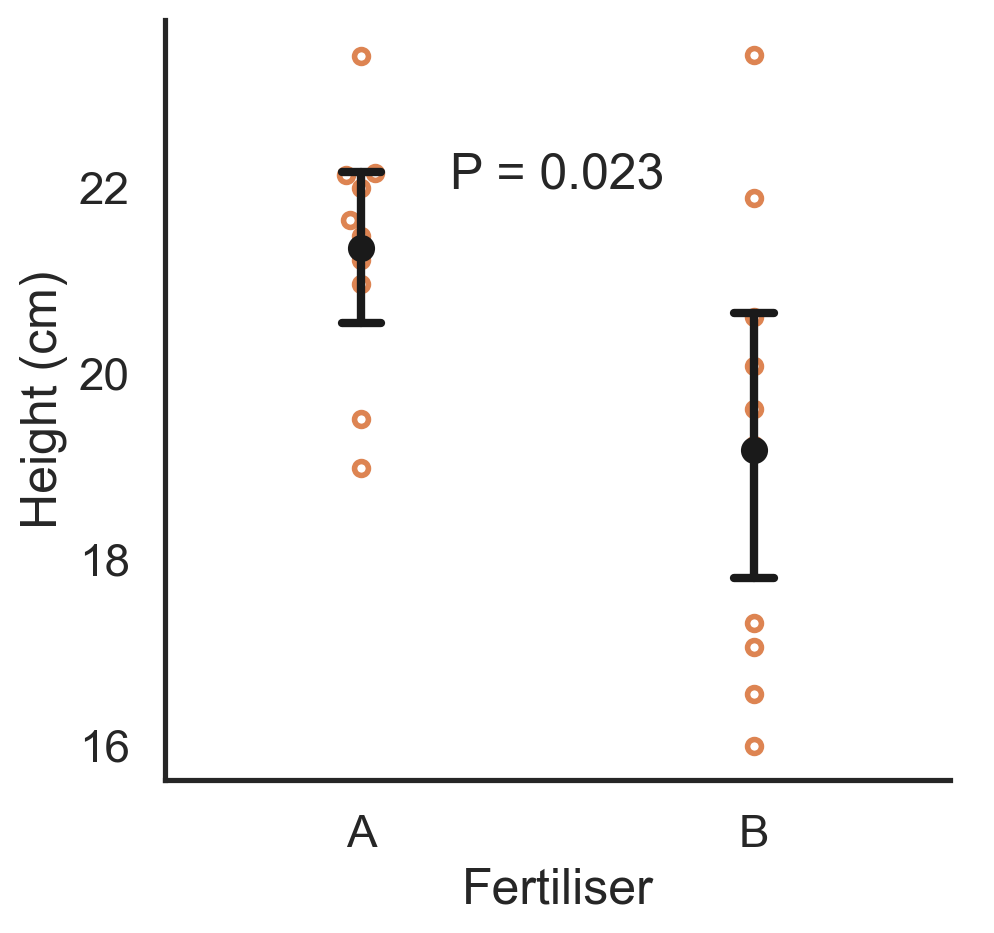

In [15]:
#| fig-align: center

g = sns.catplot(data=slicing.query('Time == "morning"'), x='Fertiliser', y='Height (cm)', kind='swarm', marker='o', zorder=0, facecolor='w', edgecolor='C1', linewidth=2);
ax = g.axes[0][0]
ax.text(s=f'P = {p2:.2g}', x=0.5, y = 22, ha='center')
sns.pointplot(ax=ax, data=slicing.query('Time == "morning"'), y='Height (cm)', x='Fertiliser', capsize=.1, color="k", linestyle="none", marker="o", linewidth=3);

:::

### Modern Guidance

- Modern statisticians prefer to think of the **compatibility** of the data with the null hypothesis. This is more intuitive than Fisher's "evidence against the null".

- The American Statistical Association now recommends avoiding rigid thresholds and labels like “significant” or “highly significant.” Instead, they suggest:

    - Reporting the exact *P*-value and letting readers judge the strength of compatibility.
    - Describing results in context, considering effect sizes, confidence intervals, and the broader scientific question.
    - Avoiding dichotomous thinking like significant/not significant or reject/fail to reject.

### How to prevent mistakes and misuse

-  In the experimental design stage, state which statistical tests will be used
-  Publish the statistical analysis plan on a dedicated website
-  Follow the plan
-  Make avaliable the raw data so that others can replicate your work
-  Any unplanned analysis (called post-hoc analysis) should be reported as preliminary and requiring further study



### Significance tests and 95% CIs

::::: {.columns}
:::: {.column width="50%"}

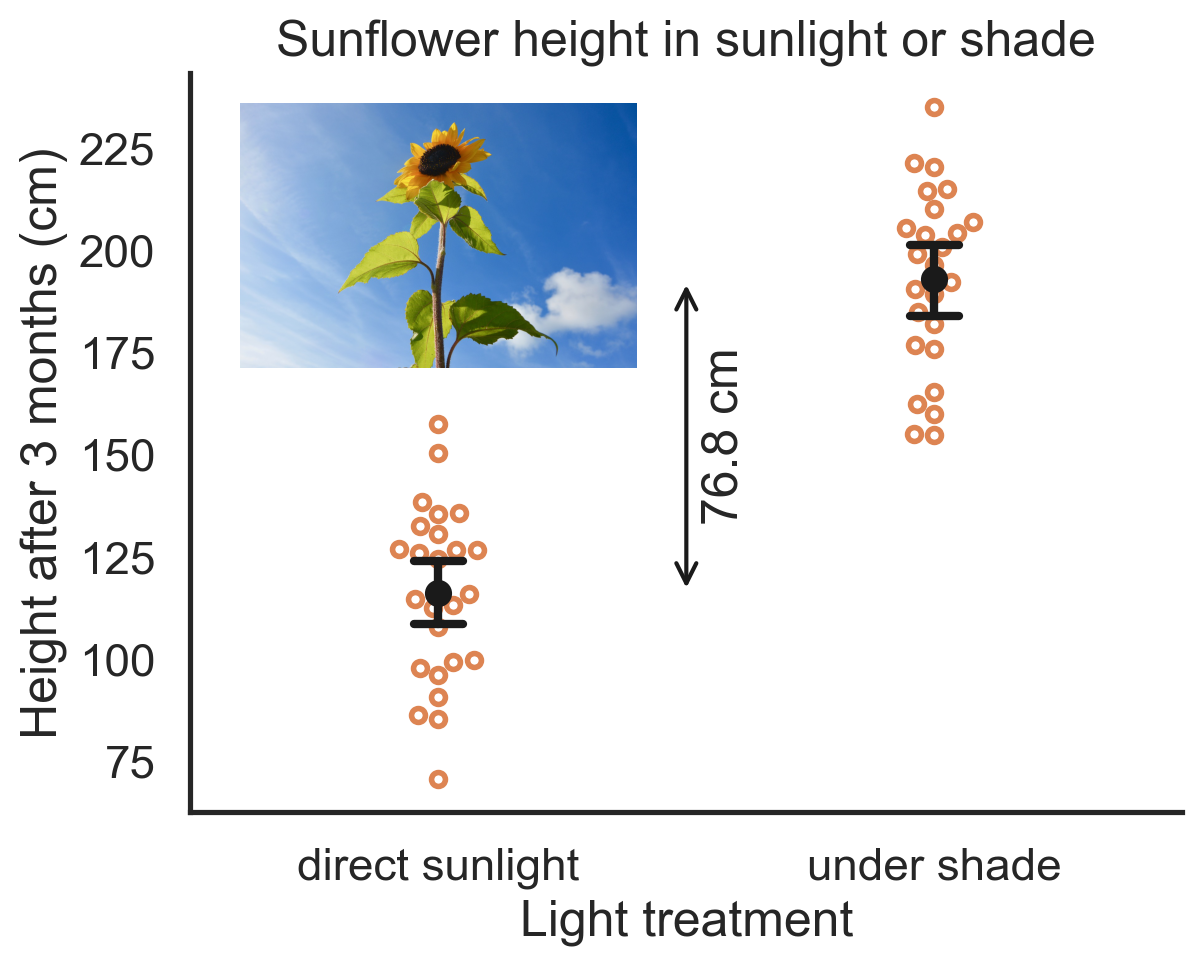

In [16]:
plot_sunflower(sunflower, diff=True)


::::
:::: {.column width="50%"}

In [17]:
#| output: false

xbar = sunflower.groupby('Treatment').mean()
y0  = float(xbar.iloc[0].values[0])
y1  = float(xbar.iloc[1].values[0])

test = ttest_ind(sunflower.query('Treatment == "under shade"')['Height after 3 months (cm)'], sunflower.query('Treatment == "direct sunlight"')['Height after 3 months (cm)'])
ci = test.confidence_interval()


*P* tells you how compatible your data are with the null hypothesis.

::: {.fragment}
In the sunflower data:
:::
- difference in means is `{python} f'{y1-y0:.1f}'` cm
- *P* = 1 x 10<sup>-19</sup>, incompatible with the null
- 95% CI of the difference is `{python} f'[{ci.low:.1f}, {ci.high:.1f}]'` cm

- The 95% CI tells you how precise your estimate of the difference in the means is

:::
::::

### Significance tests and 95% CIs

::::: {.columns}
:::: {.column width="50%"}

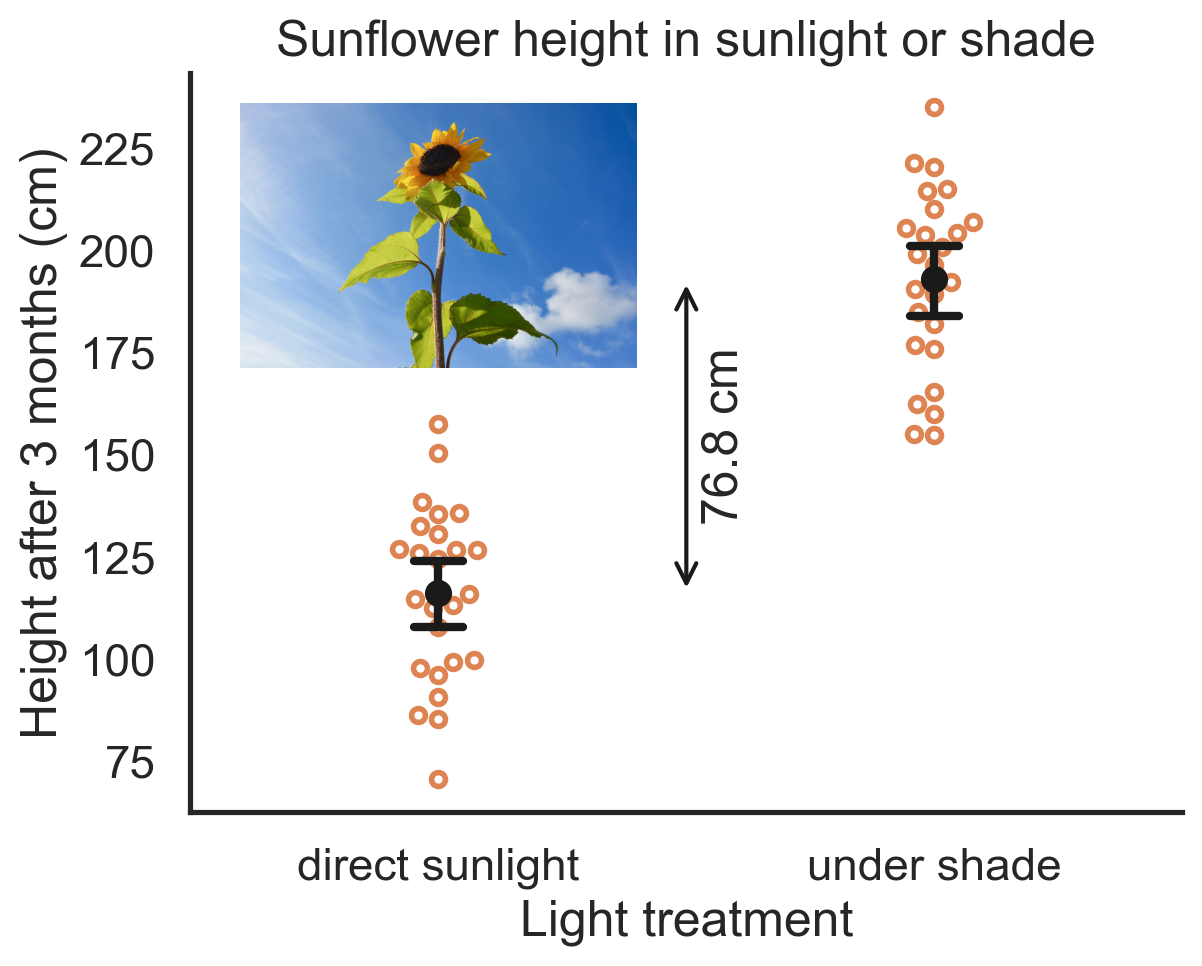

In [18]:
plot_sunflower(sunflower, diff=True)

::::
:::: {.column width="50%"}

::: {.fragment}
It turns out that:
:::

- if *P* < 0.05 (significant) then the 95% CI of the difference between the means will not contain zero,
- if *P* > 0.05 (not significant) then the 95% CI of the difference between the means will contain zero.

::: {.fragment}
You should always report both *P* and the 95% CI in a report or poster as they both contain important information.
:::
::::
:::::

### What you should take away from this lecture

- Classical statistics (the one you will see and use most) is
    - the simplest way of doing statistics (does not require mathematical and computational skills)
    - but not the only way of doing statistics
    - the least useful way of doing statistics (testing the single null hypothesis of no effect or difference)
    - easily misunderstood and misused (due to the arbitrary significance threshold of *P* < 0.05)

### What you should take away from this lecture

- The best way to interpret *P* is as the compatibility of the data with the null hypothesis
    - always report the exact value of *P* rather than, say *P* < 0.05 which is ambiguous
    - always report the size of the effect or difference either with standard error or 95% CI
    - always report which statistical test you used (e.g, two-sample *t*-test, ANOVA)
    - always report the value of the test statistic and the sample size (or degrees of freedom)

### What you should take away from this lecture

- Be sceptical and critical of significant results when *P* is just below 0.05
    - the incompatibility of the data with the null hypothesis is weak
    - the data may have been manipulated to get *P* below 0.05 (this is more common than you may think)

### What you should take away from this lecture

-  If *P* is just above 0.05 do not make the mistake of thinking that more data will bring *P* below 0.05 — it could go either way. This is a very common mistake that students make in their final year projects.

### What you should take away from this lecture

-  Do not p-hack and try not to be pressurised into p-hacking by your supervisors

### What you should take away from this lecture

-  If you need to use statistics seriously in your post-undergraduate career learn Bayesian statistics


### This week's class notebook

Five questions on five common statistical tests:

1. **Two-sample t-test**: When you want to compare the means of a numerical variable across two independent groups.
2. **Shapiro-Wilks test**: When your want to see if your data is compatible with being normally distributed.
3. **Pearson correlation test**: When you want to examine the correlation between two numerical variables.
4. **Linear regression**: When you want to examine the numerical relationship between two numerical variables, e.g., "How does a change in X affect Y?" where X and Y are numerical variables.
5. **Anova**: When you want to compare the means of a numerical variable across three or more independent groups.


In [19]:
#| output: false
# from numpy.random import normal, lognormal
# import seaborn as sns
# from scipy.stats import shapiro, ttest_ind

# while True:
# # for _ in range(1):
#     lx1 = normal(1, 0.2, 20)
#     lx2 = normal(1.1, 0.2, 20)
#     x1 = 10**lx1
#     x2 = 10**lx2
#     p1 = shapiro(x1).pvalue
#     p2 = shapiro(x2).pvalue

#     if p1 < 0.05 and p2 < 0.05:
#         lp1 = shapiro(lx1).pvalue
#         lp2 = shapiro(lx2).pvalue
#         if lp1 > 0.05 and lp2 > 0.05:
#             p = ttest_ind(lx1, lx2).pvalue
#             if p < 0.05:
#                 print(p1, p2, lp1, lp2, p)
#                 break

In [20]:
# #| output: false
# import pandas as pd
# s1 = pd.DataFrame({'strain':'BALBc' , 'time':x1.round(1)})
# s2 = pd.DataFrame({'strain':'C57' , 'time':x2.round(1)})

# df = pd.concat([s1, s2], ignore_index=True)
# df.to_csv('../Datasets/chabaudi.csv', index=False)